<a href="https://colab.research.google.com/github/Edubel77/enrutaia/blob/main/notebooks/D2_lab_1_2_backprop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Segura y correcta   -> a mano: 0.105 | Keras: 0.105
Indecisa            -> a mano: 1.079 | Keras: 1.079
Segura e incorrecta -> a mano: 3.912 | Keras: 3.912


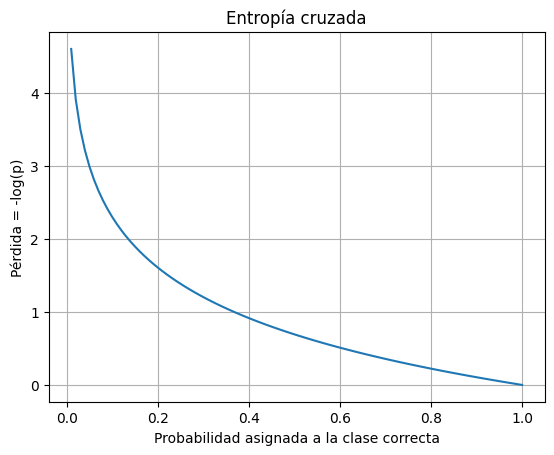

In [1]:
# Lab 1.2 - Paso 1: la función de pérdida
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)   # fija semillas de Python, NumPy y TF a la vez

# Supón que la clase correcta es la 0 (facturación).
# Tres redes distintas dan estas probabilidades:
casos = {
    "Segura y correcta  ": [0.90, 0.05, 0.05],
    "Indecisa           ": [0.34, 0.33, 0.33],
    "Segura e incorrecta": [0.02, 0.95, 0.03],
}
y_true = 0

perdida_keras = keras.losses.SparseCategoricalCrossentropy()

for nombre, probs in casos.items():
    a_mano = -np.log(probs[y_true])
    # Convertimos a tensores de TensorFlow para evitar el error de estructuras anidadas incompatibles
    con_keras = perdida_keras(tf.constant([y_true]), tf.constant([probs])).numpy()
    print(f"{nombre} -> a mano: {a_mano:.3f} | Keras: {con_keras:.3f}")

# Cómo crece la pérdida cuando baja la probabilidad de la clase correcta
p = np.linspace(0.01, 1.0, 100)
plt.plot(p, -np.log(p))
plt.xlabel("Probabilidad asignada a la clase correcta")
plt.ylabel("Pérdida = -log(p)")
plt.title("Entropía cruzada")
plt.grid(True)
plt.show()

lr=0.01 -> w tras 5 pasos:   -3.327 | tras 20 pasos:     -1.673
lr=0.1  -> w tras 5 pasos:    0.706 | tras 20 pasos:      2.919
lr=0.5  -> w tras 5 pasos:    3.000 | tras 20 pasos:      3.000
lr=1.1  -> w tras 5 pasos:   20.418 | tras 20 pasos:   -265.363


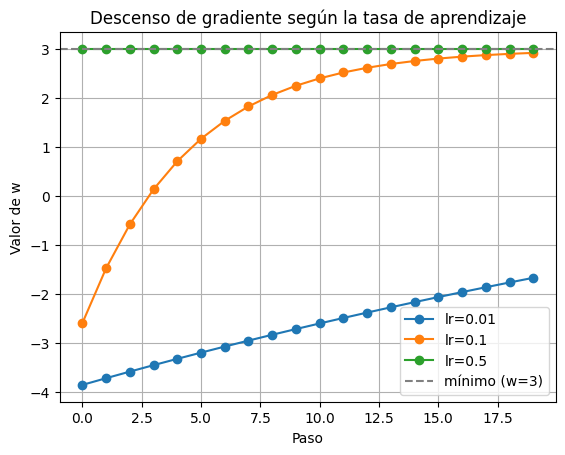

In [2]:
# Lab 1.2 - Paso 2: descenso de gradiente con GradientTape
def descenso(lr, pasos=20, w_inicial=-4.0):
    w = tf.Variable(w_inicial)          # Variable = algo que se puede entrenar
    historial = []
    for paso in range(pasos):
        with tf.GradientTape() as tape:
            perdida = (w - 3.0) ** 2    # la tape "graba" este cálculo
        grad = tape.gradient(perdida, w)   # d(pérdida)/dw, calculado solo
        w.assign_sub(lr * grad)            # w = w - lr * grad
        historial.append(w.numpy())
    return historial

for lr in [0.01, 0.1, 0.5, 1.1]:
    h = descenso(lr)
    print(f"lr={lr:<4} -> w tras 5 pasos: {h[4]:8.3f} | tras 20 pasos: {h[-1]:10.3f}")

# Gráfica de cómo se mueve w con cada tasa de aprendizaje
for lr in [0.01, 0.1, 0.5]:
    plt.plot(descenso(lr), marker="o", label=f"lr={lr}")
plt.axhline(3.0, color="gray", linestyle="--", label="mínimo (w=3)")
plt.xlabel("Paso"); plt.ylabel("Valor de w"); plt.legend(); plt.grid(True)
plt.title("Descenso de gradiente según la tasa de aprendizaje")
plt.show()

Época   0 | pérdida: 1.3090 | exactitud: 33.33%
Época  20 | pérdida: 0.5539 | exactitud: 99.00%
Época  40 | pérdida: 0.3413 | exactitud: 100.00%
Época  60 | pérdida: 0.2232 | exactitud: 100.00%
Época  80 | pérdida: 0.1457 | exactitud: 100.00%
Época  99 | pérdida: 0.0978 | exactitud: 100.00%


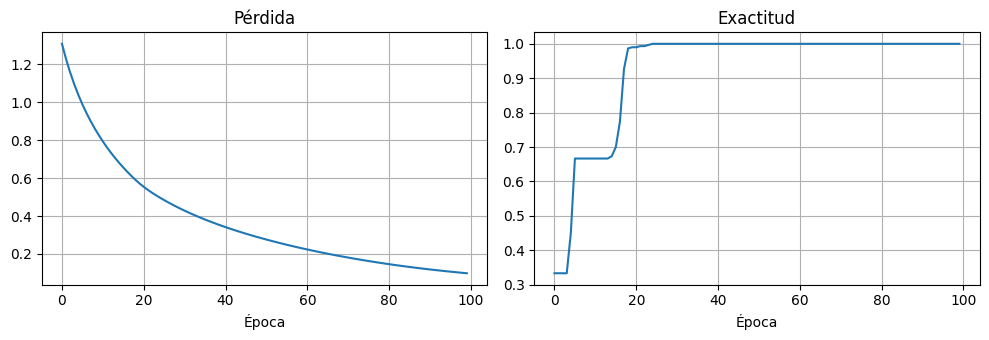

In [3]:
# Lab 1.2 - Paso 3: bucle de entrenamiento manual
from sklearn.datasets import make_blobs

# Datos: 300 puntos, 2 características, 3 clases
X, y = make_blobs(n_samples=300, centers=3, n_features=2, random_state=42)
X = ((X - X.mean(axis=0)) / X.std(axis=0)).astype("float32")   # estandarizar
y = y.astype("int32")

tf.keras.utils.set_random_seed(42)
modelo = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(3, activation="softmax"),
])
loss_fn = keras.losses.SparseCategoricalCrossentropy()

lr, epocas = 0.1, 100
hist_perdida, hist_exactitud = [], []

for epoca in range(epocas):
    with tf.GradientTape() as tape:
        y_pred = modelo(X, training=True)          # 1) forward
        perdida = loss_fn(y, y_pred)               # 2) pérdida
    grads = tape.gradient(perdida, modelo.trainable_variables)   # 3) backward
    for var, g in zip(modelo.trainable_variables, grads):        # 4) actualizar
        var.assign_sub(lr * g)

    exactitud = np.mean(np.argmax(y_pred.numpy(), axis=1) == y)
    hist_perdida.append(float(perdida)); hist_exactitud.append(exactitud)
    if epoca % 20 == 0 or epoca == epocas - 1:
        print(f"Época {epoca:3d} | pérdida: {float(perdida):.4f} | exactitud: {exactitud:.2%}")

# Curvas de aprendizaje
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist_perdida);   ax[0].set_title("Pérdida");   ax[0].set_xlabel("Época")
ax[1].plot(hist_exactitud); ax[1].set_title("Exactitud"); ax[1].set_xlabel("Época")
for a in ax: a.grid(True)
plt.tight_layout(); plt.show()

Bucle manual       -> pérdida final: 0.0978
fit() batch=300    -> pérdida final: 0.0978
fit() batch=32     -> pérdida final: 0.0021


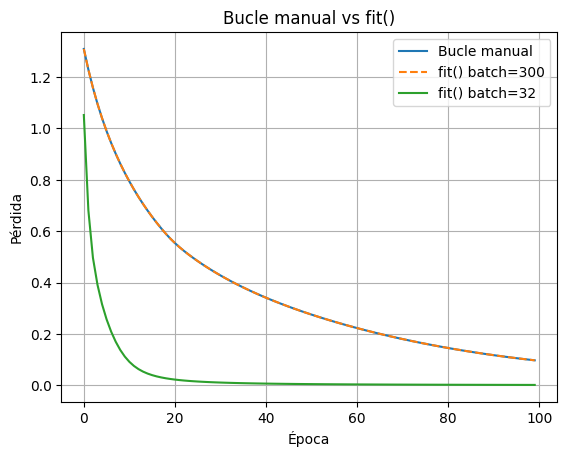

In [4]:
# Lab 1.2 - Paso 4: el mismo entrenamiento con fit()
def crear_modelo():
    tf.keras.utils.set_random_seed(42)            # misma semilla -> mismos pesos iniciales
    return keras.Sequential([
        keras.Input(shape=(2,)),
        keras.layers.Dense(8, activation="relu"),
        keras.layers.Dense(3, activation="softmax"),
    ])

# A) Igual que tu bucle: SGD, lr=0.1, todos los datos en cada paso (batch completo)
modelo_fit = crear_modelo()
modelo_fit.compile(optimizer=keras.optimizers.SGD(learning_rate=0.1),
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
hist_a = modelo_fit.fit(X, y, epochs=100, batch_size=len(X), verbose=0)

# B) Lo habitual: mini-lotes de 32 ejemplos
modelo_mini = crear_modelo()
modelo_mini.compile(optimizer=keras.optimizers.SGD(learning_rate=0.1),
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
hist_b = modelo_mini.fit(X, y, epochs=100, batch_size=32, verbose=0)

print(f"Bucle manual       -> pérdida final: {hist_perdida[-1]:.4f}")
print(f"fit() batch=300    -> pérdida final: {hist_a.history['loss'][-1]:.4f}")
print(f"fit() batch=32     -> pérdida final: {hist_b.history['loss'][-1]:.4f}")

plt.plot(hist_perdida, label="Bucle manual")
plt.plot(hist_a.history["loss"], "--", label="fit() batch=300")
plt.plot(hist_b.history["loss"], label="fit() batch=32")
plt.xlabel("Época"); plt.ylabel("Pérdida"); plt.legend(); plt.grid(True)
plt.title("Bucle manual vs fit()")
plt.show()

Optimizador | lr=0.001  | lr=0.01   | lr=0.1   
SGD        | 1.1654    | 0.5661    | 0.0252   
Momentum   | 0.5792    | 0.0296    | 0.0006   
Adam       | 0.6453    | 0.0048    | 0.0000   


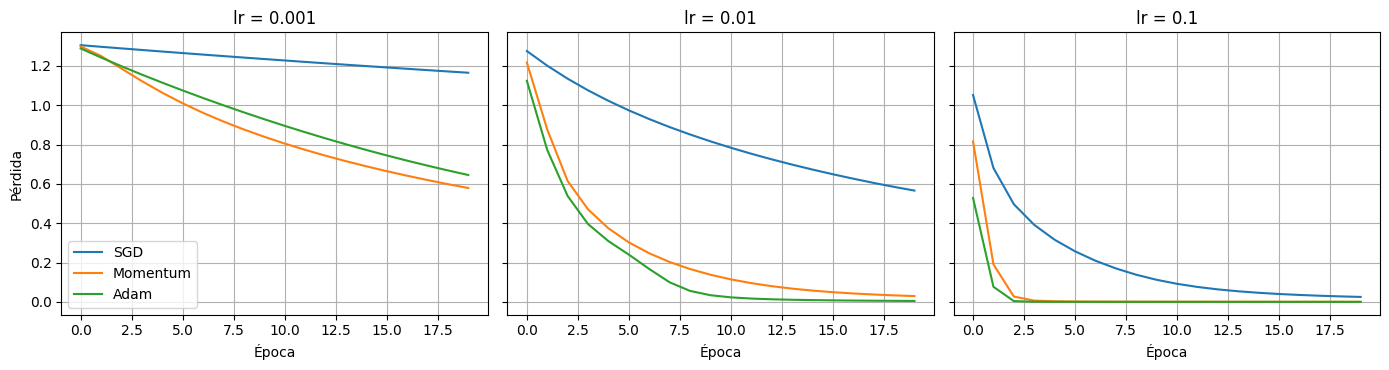

In [5]:
# Lab 1.2 - Paso 5: comparar optimizadores
optimizadores = {
    "SGD":      lambda lr: keras.optimizers.SGD(learning_rate=lr),
    "Momentum": lambda lr: keras.optimizers.SGD(learning_rate=lr, momentum=0.9),
    "Adam":     lambda lr: keras.optimizers.Adam(learning_rate=lr),
}
tasas = [0.001, 0.01, 0.1]
resultados = {}

for nombre, crear_opt in optimizadores.items():
    for lr in tasas:
        m = crear_modelo()                       # misma semilla en los 9 casos
        m.compile(optimizer=crear_opt(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        h = m.fit(X, y, epochs=20, batch_size=32, verbose=0)
        resultados[(nombre, lr)] = h.history["loss"]

# Tabla de pérdida final
print(f"{'Optimizador':<10} | " + " | ".join(f"lr={lr:<6}" for lr in tasas))
for nombre in optimizadores:
    print(f"{nombre:<10} | " + " | ".join(f"{resultados[(nombre, lr)][-1]:<9.4f}" for lr in tasas))

# Gráficas: una por tasa de aprendizaje
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for i, lr in enumerate(tasas):
    for nombre in optimizadores:
        ax[i].plot(resultados[(nombre, lr)], label=nombre)
    ax[i].set_title(f"lr = {lr}"); ax[i].set_xlabel("Época"); ax[i].grid(True)
ax[0].set_ylabel("Pérdida"); ax[0].legend()
plt.tight_layout(); plt.show()

Con la tasa de aprendizaje más baja (0.001), Momentum logró la menor pérdida (0.5792), superando ligeramente a Adam (0.6453) y dejando atrás a SGD (1.1654), ya que acumula impulso de pasos anteriores para avanzar más rápido cuando los pasos son pequeños. Dentro del rango evaluado (0.001 a 0.1), la pérdida final disminuyó al aumentar la tasa de aprendizaje (sin extrapolar más allá de 0.1, pues tasas demasiado altas provocan divergencia), y en las gráficas las curvas de Momentum y Adam con lr = 0.1 bajan de forma suave, sin salto. Para empezar un proyecto nuevo sin hacer pruebas previas, elegiría Adam, porque mantuvo un rendimiento sólido con tasas pequeñas y alcanzó una pérdida menor a 0.0001 con lr = 0.1, demostrando ser el más versátil y confiable

In [6]:
# Proyecto EnrutaIA - Paso 6: explorar el dataset candidato (MASSIVE, español)
from datasets import load_dataset
import pandas as pd

ds = load_dataset("mteb/amazon_massive_intent", "es")
print(ds)                                   # splits, columnas y tamaños

train = ds["train"].to_pandas()
print("\nColumnas:", list(train.columns))
print("\nEjemplos:")
print(train.sample(8, random_state=42).to_string())

conteo = train["label"].value_counts()
print(f"\nNúmero de clases: {train['label'].nunique()}")
print(f"Clase más frecuente : {conteo.index[0]} ({conteo.iloc[0]} ejemplos)")
print(f"Clase menos frecuente: {conteo.index[-1]} ({conteo.iloc[-1]} ejemplos)")

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/51 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'label', 'label_text', 'text', 'lang'],
        num_rows: 11514
    })
    test: Dataset({
        features: ['id', 'label', 'label_text', 'text', 'lang'],
        num_rows: 2974
    })
    validation: Dataset({
        features: ['id', 'label', 'label_text', 'text', 'lang'],
        num_rows: 2033
    })
})

Columnas: ['id', 'label', 'label_text', 'text', 'lang']

Ejemplos:
          id              label         label_text                                                                        text lang
9710   14447         qa_factoid         qa_factoid  cuál es el ingreso per cápita promedio entre las personas de asia y europa   es
8313   12365    transport_query    transport_query                                            a que hora sale el tren de lagos   es
2960    4369    iot_hue_lightup    iot_hue_lightup                                                           conecta las luces   es
3058    4507         play_music   

In [7]:
# Proyecto EnrutaIA - Paso 6b: ¿60 intenciones o 18 dominios?
train["dominio"] = train["label"].str.split("_").str[0]

conteo_dom = train["dominio"].value_counts()
print(f"Número de dominios: {train['dominio'].nunique()}\n")
print(conteo_dom.to_string())
print(f"\nRazón más/menos frecuente -> intenciones: {conteo.iloc[0] / conteo.iloc[-1]:.0f}x | "
      f"dominios: {conteo_dom.iloc[0] / conteo_dom.iloc[-1]:.0f}x")

Número de dominios: 18

dominio
calendar          1688
play              1377
qa                1183
email              953
iot                769
general            652
weather            573
transport          571
lists              539
news               503
recommendation     433
datetime           402
social             391
alarm              390
music              332
audio              290
takeaway           257
cooking            211

Razón más/menos frecuente -> intenciones: 202x | dominios: 8x


Con la tasa de aprendizaje más baja (0.001), Momentum logró la menor pérdida (0.5792), superando ligeramente a Adam (0.6453) y dejando atrás a SGD (1.1654), ya que acumula impulso de pasos anteriores para avanzar más rápido cuando los pasos son pequeños. Dentro del rango evaluado (0.001 a 0.1), la pérdida final disminuyó al aumentar la tasa de aprendizaje (sin extrapolar más allá de 0.1, pues tasas demasiado altas provocan divergencia), las curvas bajaron de forma suave, sin saltos” o “Momentum mostró oscilaciones en las primeras épocas y Adam con lr = 0.1— para confirmar que no haya saltos o dientes de sierra antes de descartar inestabilidad. Para empezar un proyecto nuevo sin hacer pruebas previas, elegiría Adam, porque mantuvo un rendimiento sólido con tasas pequeñas y alcanzó una pérdida menor a 0.0001 con lr = 0.1, demostrando ser el más versátil y confiable.